# FL-ATTACK-003.5 — Countermeasure evaluation (before/after)

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Compare defences on each attack before and after, including secure aggregation (which gives no poisoning robustness).

## 2. Scientific background
See tasks 3.1–3.4 and [kairouz2021].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Which defences reduce ASR/accuracy damage and at what clean-accuracy cost?

## 4. Hypotheses
- **H1.** Secure aggregation and HE leave backdoor ASR unchanged; robust rules/norm bounds reduce it.

## 5. Mathematical formulation
Defence effect = metric_after − metric_before with CIs.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks.py`, `defenses.py`, `fl.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.aggregators.mean import WeightedMean
from federated_learning.aggregators.robust import CoordinateMedian, TrimmedMean, Krum
from federated_learning.aggregators.defenses import ClippedMean
r = np.random.default_rng(SEED); D = r.normal(1.0, .05, (10, 30)).astype(np.float32); D[:2] = -50.0; W = np.ones(10)
for a in (WeightedMean(), CoordinateMedian(), TrimmedMean(0.25), Krum(2, 1)):
    print(f"{type(a).__name__:18s} max|agg-1| = {np.abs(a.aggregate(D, W) - 1.0).max():.3f}")

WeightedMean       max|agg-1| = 10.245
CoordinateMedian   max|agg-1| = 0.067
TrimmedMean        max|agg-1| = 0.077
Krum               max|agg-1| = 0.128


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.5` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_5_runs.csv')

,attack,defense,seed,metric,value,clean_acc
0,backdoor-medium,none(mean),0,asr,0.9965,0.7408
1,backdoor-medium,none(mean),1,asr,0.9972,0.7422
2,backdoor-medium,none(mean),2,asr,0.9979,0.7414
3,backdoor-medium,clip(C=median norm),0,asr,0.9385,0.7631
4,backdoor-medium,clip(C=median norm),1,asr,0.7928,0.7614
5,backdoor-medium,clip(C=median norm),2,asr,0.8860,0.7592
6,backdoor-medium,clip+noise(sigma=0.5),0,asr,0.9489,0.7647
7,backdoor-medium,clip+noise(sigma=0.5),1,asr,0.7756,0.7536
8,backdoor-medium,clip+noise(sigma=0.5),2,asr,0.7852,0.7592
9,backdoor-medium,median,0,asr,0.2700,0.7783


## 12. Metrics collection
Metric definitions: MEASURED over seeds: attack metric (ASR / AUC / success rate), clean accuracy, defense cost. Intensity levels low/medium/high are defined in docs/fl_attack_003/attack_methodology.md.

In [8]:
show_csv('task_3_5_summary.csv')

,attack,defense,metric,value,ci,clean_acc,eps
0,backdoor-high,anomaly_filter,asr,0.0536,"[-0.103, 0.210]",0.7803,NaN
1,backdoor-high,clip(C=median norm),asr,0.9843,"[0.969, 1.000]",0.7456,NaN
2,backdoor-high,clip+noise(sigma=0.5),asr,0.9793,"[0.949, 1.009]",0.7425,NaN
3,backdoor-high,he_ckks(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
4,backdoor-high,median,asr,0.2997,"[-0.189, 0.788]",0.7726,NaN
5,backdoor-high,multi-krum,asr,0.0536,"[-0.103, 0.210]",0.7803,NaN
6,backdoor-high,none(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
7,backdoor-high,secagg(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
8,backdoor-high,smpc_norm_bound(2x median),asr,0.0539,"[-0.104, 0.211]",0.7802,NaN
9,backdoor-high,trimmed_mean(0.3),asr,0.3810,"[-0.158, 0.920]",0.7695,NaN


## 13. Statistical analysis
95% CIs over seeds; AUC/ASR CIs may extend beyond [0,1] because they are t-intervals on few seeds (reported as computed).

In [9]:
show_csv('task_3_5_summary.csv', 30)

,attack,defense,metric,value,ci,clean_acc,eps
0,backdoor-high,anomaly_filter,asr,0.0536,"[-0.103, 0.210]",0.7803,NaN
1,backdoor-high,clip(C=median norm),asr,0.9843,"[0.969, 1.000]",0.7456,NaN
2,backdoor-high,clip+noise(sigma=0.5),asr,0.9793,"[0.949, 1.009]",0.7425,NaN
3,backdoor-high,he_ckks(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
4,backdoor-high,median,asr,0.2997,"[-0.189, 0.788]",0.7726,NaN
5,backdoor-high,multi-krum,asr,0.0536,"[-0.103, 0.210]",0.7803,NaN
6,backdoor-high,none(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
7,backdoor-high,secagg(mean),asr,0.9993,"[0.998, 1.001]",0.6902,NaN
8,backdoor-high,smpc_norm_bound(2x median),asr,0.0539,"[-0.104, 0.211]",0.7802,NaN
9,backdoor-high,trimmed_mean(0.3),asr,0.3810,"[-0.158, 0.920]",0.7695,NaN


## 14. Visualizations

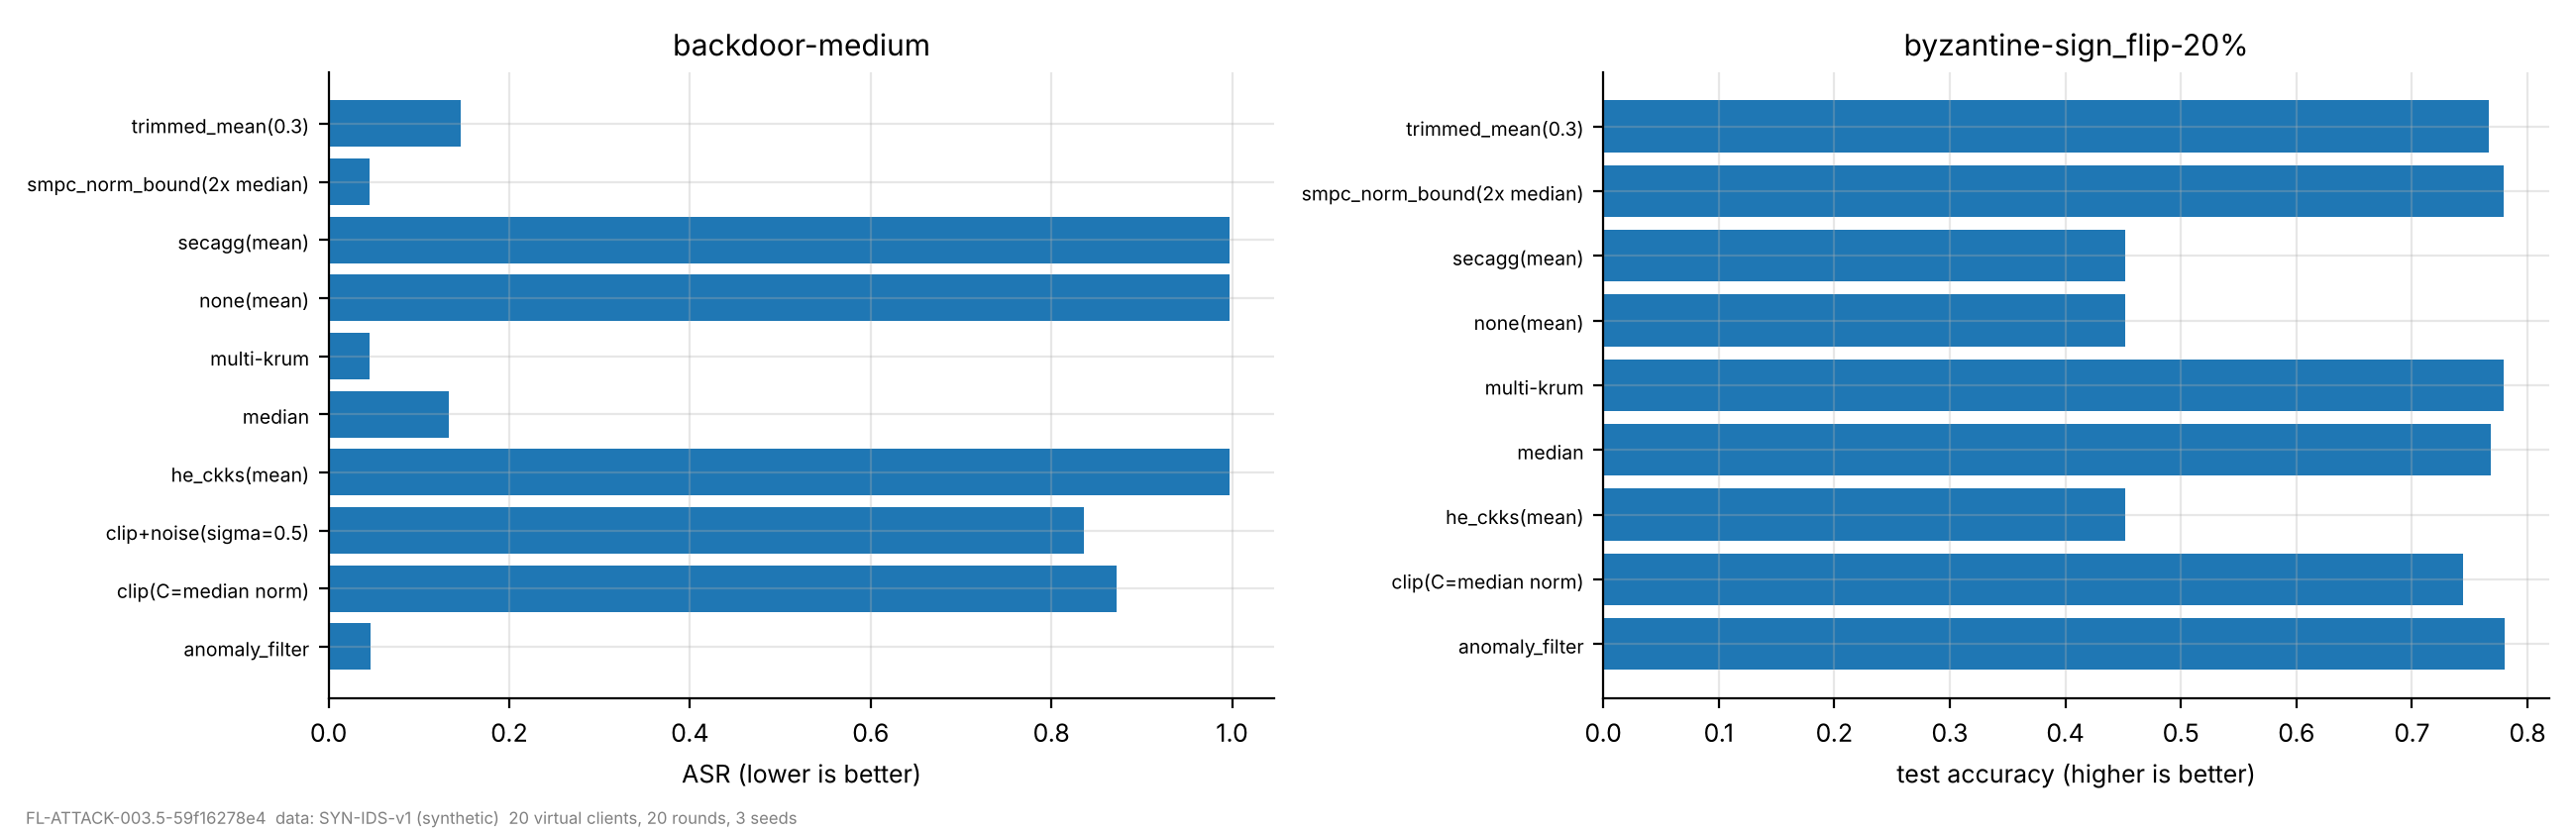

In [10]:
show_fig('task_3_5_countermeasures.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Printed table; SecAgg/HE rows equal 'none' for backdoor ASR as expected.

In [11]:
d = pd.read_csv(RES / 'task_3_5_summary.csv'); print(d[d.metric=='asr'][['attack','defense','value','clean_acc']].round(3).to_string(index=False))

         attack                    defense  value  clean_acc
  backdoor-high             anomaly_filter  0.054      0.780
  backdoor-high        clip(C=median norm)  0.984      0.746
  backdoor-high      clip+noise(sigma=0.5)  0.979      0.742
  backdoor-high              he_ckks(mean)  0.999      0.690
  backdoor-high                     median  0.300      0.773
  backdoor-high                 multi-krum  0.054      0.780
  backdoor-high                 none(mean)  0.999      0.690
  backdoor-high               secagg(mean)  0.999      0.690
  backdoor-high smpc_norm_bound(2x median)  0.054      0.780
  backdoor-high          trimmed_mean(0.3)  0.381      0.770
backdoor-medium             anomaly_filter  0.046      0.780
backdoor-medium        clip(C=median norm)  0.872      0.761
backdoor-medium      clip+noise(sigma=0.5)  0.837      0.759
backdoor-medium              he_ckks(mean)  0.997      0.741
backdoor-medium                     median  0.134      0.778
backdoor-medium         

## 16. Limitations
- Adaptive attacks against defences not evaluated.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Defences must be chosen per threat; confidentiality tools do not give integrity.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`blanchard2017`, `yin2018`, `bonawitz2017`, `kairouz2021` — details in `docs/fl_attack_003/references.md`.